In [4]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


### Load criteo dataset

In [5]:
df = pd.read_csv("data/criteo-uplift-v2.1.csv")
print(df.columns.tolist())
df.head()

['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


### Calculate sample size using MDE of 0.5%

In [3]:
# Empirical baseline from control group
p0 = df[df["treatment"] == 0]["conversion"].mean()

# MDE: +0.5pp marginal probability → convert both to log-odds
mde = 0.005
p1 = p0 + mde

logit = lambda p: np.log(p / (1 - p))
delta = logit(p1) - logit(p0)  # effect size in log-odds

# Asymptotic variance of β̂₁ in logistic regression (balanced design):
# Var(β̂₁) = (a0 + a1) / (N * a0 * a1)  where N = per-arm n
a0 = p0 * (1 - p0)
a1 = p1 * (1 - p1)

alpha = 0.05
power = 0.80

z_alpha = stats.norm.ppf(1 - alpha / 2)
z_beta  = stats.norm.ppf(power)

n_per_arm = (z_alpha + z_beta) ** 2 * (a0 + a1) / (a0 * a1 * delta ** 2)
n_total   = 2 * n_per_arm

print(f"Baseline conversion rate (control):  {p0:.4%}")
print(f"Target conversion rate (treatment):  {p1:.4%}")
print()
print(f"Log-odds baseline:                   {logit(p0):.6f}")
print(f"Log-odds treatment:                  {logit(p1):.6f}")
print(f"Effect size Δ (log-odds):            {delta:.6f}")
print()
print(f"z_alpha/2:  {z_alpha:.4f}")
print(f"z_beta:     {z_beta:.4f}")
print()
print(f"Required n per arm:  {int(np.ceil(n_per_arm)):,}")
print(f"Required n total:    {int(np.ceil(n_total)):,}")

Baseline conversion rate (control):  0.1938%
Target conversion rate (treatment):  0.6938%

Log-odds baseline:                   -6.244372
Log-odds treatment:                  -4.963839
Effect size Δ (log-odds):            1.280533

z_alpha/2:  1.9600
z_beta:     0.8416

Required n per arm:  3,170
Required n total:    6,340


### Sample size with an imbalanced allocation ratio

The above assumes a 1:1 (balanced) split. More generally, for allocation ratio `r = n1/n0` (treatment:control), the per-arm variance is `Var(β̂₁) = 1/(n0*a0) + 1/(n1*a1)`. Substituting `n0 = N/(1+r)`, `n1 = r*N/(1+r)` gives the required total N as a function of `r`; `r=1` recovers the balanced formula above.

We use `r ≈ 5.667`, the actual observed treatment:control ratio in this data (see the SRM check below), to see how much more total traffic an imbalanced design like that needs for the same MDE/power.

In [ ]:
# Sample size for an imbalanced allocation ratio r = n1/n0 (treatment:control)
# Var(β̂₁) = 1/(n0*a0) + 1/(n1*a1); n0 = N/(1+r), n1 = r*N/(1+r)
# => N = (z_a + z_b)^2 * (1+r) * (1/a0 + 1/(r*a1)) / delta^2

r = 5.666672389299249  # observed treatment:control ratio (see SRM check below)

n_total_imbalanced = (z_alpha + z_beta) ** 2 * (1 + r) * (1 / a0 + 1 / (r * a1)) / delta ** 2
n0_imbalanced = n_total_imbalanced / (1 + r)
n1_imbalanced = n_total_imbalanced - n0_imbalanced

print(f"Allocation ratio r (treatment:control):  {r:.4f}:1")
print()
print(f"Required n control (n0):    {int(np.ceil(n0_imbalanced)):,}")
print(f"Required n treatment (n1):  {int(np.ceil(n1_imbalanced)):,}")
print(f"Required n total:           {int(np.ceil(n_total_imbalanced)):,}")
print()
print(f"Balanced (1:1) n total:     {int(np.ceil(n_total)):,}")
print(f"Inflation vs. balanced:     {n_total_imbalanced / n_total:.2f}x")


Allocation ratio r (treatment:control):  52.0000:1

Required n control (n0):    2,489
Required n treatment (n1):  129,405
Required n total:           131,893

Balanced (1:1) n total:     6,340
Inflation vs. balanced:     20.80x


### Do SRM checks
- Note: don't actually know what the expect treatment:control ratio is, so just assume it is 1:1 for now

In [4]:
# Check number of treatment, controls in the data
observed_control = df[df['treatment'] == 0].shape[0]
observed_treatment = df[df['treatment'] == 1].shape[0]
total = observed_control + observed_treatment
observed_ratio = observed_treatment / observed_control

print(observed_control, observed_treatment, observed_ratio) ## 5.7 times as many treatment

2096937 11882655 5.666672389299249


In [46]:
# Run chi square test on observed ratio, using 1:1 assumption
expected_control = total / 2
expected_treatment = total / 2

chi2_stat, p_value = stats.chisquare(
    f_obs=[observed_control, observed_treatment],
    f_exp=[expected_control, expected_treatment],
)

print(f"Observed: control={observed_control:,}  treatment={observed_treatment:,}  ratio={observed_ratio:.4f}:1")
print(f"Expected (1:1): control={expected_control:,.0f}  treatment={expected_treatment:,.0f}")
print()
print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"p-value:              {p_value:.4e}")
print()
if p_value < 0.01:
    print("SRM DETECTED: observed allocation significantly deviates from 1:1 (p < 0.01)")
else:
    print("No significant SRM detected")

Observed: control=2,096,937  treatment=11,882,655  ratio=5.6667:1
Expected (1:1): control=6,989,796  treatment=6,989,796

Chi-square statistic: 6850005.1200
p-value:              0.0000e+00

SRM DETECTED: observed allocation significantly deviates from 1:1 (p < 0.01)


As expected, there is SRM (can probably tell even without running the test). The 1:1 assumption is probably naive anyway. But if it was indeed meant to be 1:1, then probably worth diagnosing the problem. Assignment or logging probably went wrong

We replicate this on the exposure group vs control. We assume that there is no self-selection involved in exposure, in case we intend to measure intent-to-treat (ITT) rather than average treatment effect (ATE). In reality, ITT might be more valuable since we want to know the effect of actually receiving the treatemnt, not just being allocated the treatment.

In [45]:
df.loc[df.exposure > df.treatment].shape[0] ## data is all good
df.loc[df.treatment==0].shape[0] / df.loc[df.exposure == 1].shape[0]

4.896959917050433

The analysis is 5 times more likely to happen for 

### Do A/A tests to check conversion rates for control
- Split control group in control and pseudo treatmnet, check diff in conversion rates are only true 5% of the time, ideally less
- Simulate the splits 1000 times

In [6]:
# A/A test: randomly split the control group into two pseudo-arms,
# test diff in means on conversion, repeat 1000x, check false-positive rate
rng = np.random.default_rng(42)

control_conversion = df.loc[df["treatment"] == 0, "conversion"].values
n_control = len(control_conversion)
half = n_control // 2

n_sims = 1000
alpha = 0.05

p_values = np.empty(n_sims)
for i in range(n_sims):
    perm = rng.permutation(n_control)
    pseudo_a = control_conversion[perm[:half]]
    pseudo_b = control_conversion[perm[half:]]
    _, p_values[i] = stats.ttest_ind(pseudo_a, pseudo_b)

prop_significant = (p_values < alpha).mean()

print(f"Control group size:              {n_control:,}")
print(f"Pseudo-arm size:                 {half:,}")
print(f"Number of A/A simulations:       {n_sims}")
print(f"Proportion stat. sig. (p<{alpha}):  {prop_significant:.4f}")
print(f"Expected under null (no effect): {alpha:.4f}")

Control group size:              2,096,937
Pseudo-arm size:                 1,048,468
Number of A/A simulations:       1000
Proportion stat. sig. (p<0.05):  0.0440
Expected under null (no effect): 0.0500


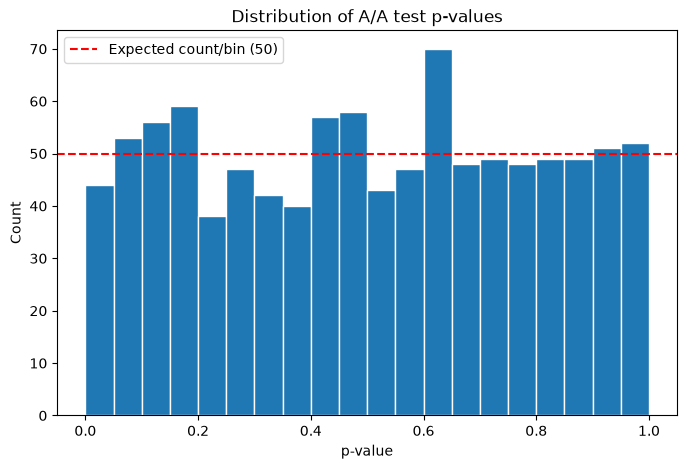

KS statistic: 0.0267
KS p-value:   0.4652
Fail to reject H0: p-values consistent with Uniform(0,1)


In [7]:
# Histogram of A/A p-values + KS test against Uniform(0,1)
ks_stat, ks_p = stats.kstest(p_values, "uniform")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(p_values, bins=20, range=(0, 1), edgecolor="white")
ax.axhline(n_sims / 20, color="red", linestyle="--", label=f"Expected count/bin ({n_sims/20:.0f})")
ax.set_xlabel("p-value")
ax.set_ylabel("Count")
ax.set_title("Distribution of A/A test p-values")
ax.legend()
plt.show()

print(f"KS statistic: {ks_stat:.4f}")
print(f"KS p-value:   {ks_p:.4f}")
if ks_p < 0.05:
    print("Reject H0: p-values do NOT follow Uniform(0,1)")
else:
    print("Fail to reject H0: p-values consistent with Uniform(0,1)")

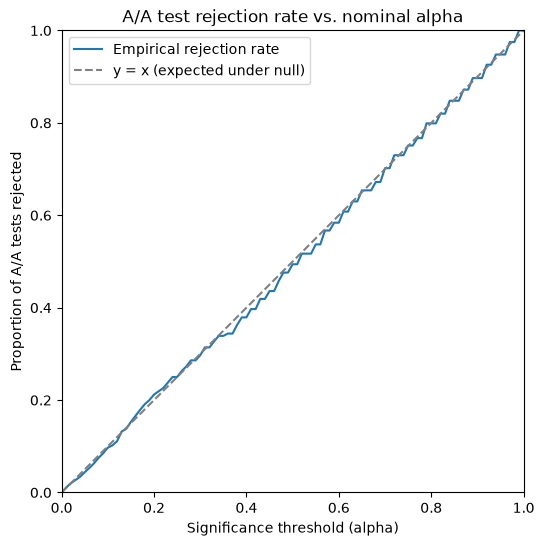

In [8]:
# Rejection rate vs. nominal alpha threshold (calibration / P-P plot)
alphas = np.linspace(0, 1, 101)
rejection_rate = np.array([(p_values < a).mean() for a in alphas])

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(alphas, rejection_rate, label="Empirical rejection rate")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="y = x (expected under null)")
ax.set_xlabel("Significance threshold (alpha)")
ax.set_ylabel("Proportion of A/A tests rejected")
ax.set_title("A/A test rejection rate vs. nominal alpha")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.legend()
plt.show()

Nice, so all looks good. No spikes, distribution of pvalues looks normal, rejection rate roughly y=x line. Dream experimental scenario

If there are indications that p values are note U(0,1), might have to investigate further. Maybe observations are not iid - correlations in the data for example, so you see p-values congretating at <5% (difference picked up is stuff like user segment)

## Variance reduction for estimator: stratified sampling

Startification takes place before the experiment is conducted. But since it is already done, we check if stratification would have lowered the variance. To do this, I basically calculate the pooled variance with weighted within-group variance

In [9]:
# Stratify on f2: create 5 bins, then compare pooled variance
# of conversion vs. the weighted within-stratum variance
#
# f2 has a sentinel/imputed value (its min, 8.214383) that alone accounts for
# ~52% of rows -- almost certainly a "missing" placeholder. That mass point
# straddles the 25th/50th percentile, so a plain pd.qcut(q=5) collapses to
# only 3 bins (duplicate edges get dropped). Instead: carve the sentinel out
# as its own stratum, then quantile-bin the remaining continuous values into
# 4 bins, for 5 strata total.

n_bins = 5
sentinel = df["f2"].min()
is_sentinel = df["f2"] == sentinel

df["f2_bin"] = -1
df.loc[is_sentinel, "f2_bin"] = 0
df.loc[~is_sentinel, "f2_bin"] = (
    pd.qcut(df.loc[~is_sentinel, "f2"], q=n_bins - 1, labels=False, duplicates="drop") + 1
)

strata = df.groupby("f2_bin")["conversion"].agg(n="count", var="var", mean="mean")
strata["weight"] = strata["n"] / len(df)

grand_mean = df["conversion"].mean()

pooled_variance = df["conversion"].var()                                   # Var(Y), no stratification
weighted_within_variance = (strata["weight"] * strata["var"]).sum()        # E_h[Var(Y | stratum h)]
weighted_between_variance = (strata["weight"] * (strata["mean"] - grand_mean) ** 2).sum()

print(strata)
print()
print(f"Pooled variance (unstratified):      {pooled_variance:.6f}")
print(f"Weighted within-stratum variance:    {weighted_within_variance:.6f}")
print(f"Weighted between-stratum variance:   {weighted_between_variance:.6f}")
print(f"Within + Between (should ~= pooled): {weighted_within_variance + weighted_between_variance:.6f}")
print()

reduction = pooled_variance - weighted_within_variance
pct_reduction = reduction / pooled_variance * 100
print(f"Variance reduction from stratifying on f2: {reduction:.6f} ({pct_reduction:.2f}%)")

if weighted_within_variance < pooled_variance:
    print("Stratifying on f2 reduces variance of the conversion estimator.")
else:
    print("Stratifying on f2 does NOT reduce variance -- f2 bins carry ~no information about conversion.")


              n       var      mean    weight
f2_bin                                       
0       7303429  0.000089  0.000089  0.522435
1       1669044  0.019120  0.019500  0.119391
2       1669041  0.003140  0.003150  0.119391
3       1669037  0.001028  0.001029  0.119391
4       1669041  0.000362  0.000362  0.119391

Pooled variance (unstratified):      0.002908
Weighted within-stratum variance:    0.002870
Weighted between-stratum variance:   0.000038
Within + Between (should ~= pooled): 0.002908

Variance reduction from stratifying on f2: 0.000038 (1.31%)
Stratifying on f2 reduces variance of the conversion estimator.


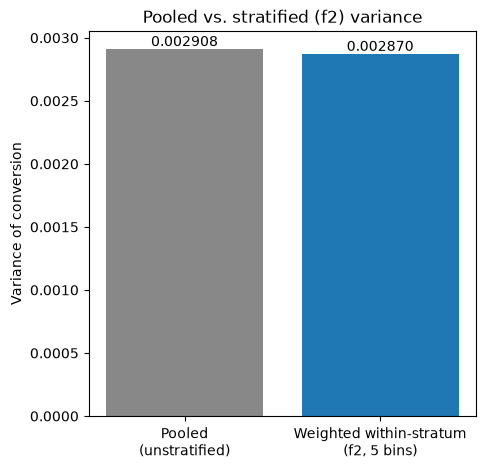

In [10]:
# Visualize pooled vs. weighted within-stratum variance
fig, ax = plt.subplots(figsize=(5, 5))
bars = ax.bar(
    ["Pooled\n(unstratified)", "Weighted within-stratum\n(f2, 5 bins)"],
    [pooled_variance, weighted_within_variance],
    color=["#888888", "#1f77b4"],
)
ax.bar_label(bars, fmt="%.6f")
ax.set_ylabel("Variance of conversion")
ax.set_title("Pooled vs. stratified (f2) variance")
plt.show()


## CUPED estimator

CUPED: `Y_cuped = Y - theta * (X - X_bar)`, with `theta = Cov(X, Y) / Var(X)` chosen to minimize `Var(Y_cuped)`. (Equivalent to the `y_hat = y + theta*x` form up to sign/centering: `Y - theta*(X - X_bar) = Y + (-theta)*X + theta*X_bar`.)

This dataset has no real pre-treatment period -- `conversion`/`visit`/`exposure` are all measured post-assignment. No timestamp to split on. Create arbitrary pre-post split to demonstrate the mechanics: shuffle the rows and split in half, treat the first half's `conversion` as a synthetic "pre-period" `x` and the second half's `conversion` as the outcome `y`, paired index-for-index after the shuffle. 

This pairing is arbitrary (not the same unit measured twice), so it's not a causally valid pre-period -- just a way to see the CUPED math run end-to-end.

In [49]:
# CUPED: Y_cuped = Y - theta*(X - X_bar), theta = Cov(X,Y)/Var(X)
rng = np.random.default_rng(42)
perm = rng.permutation(len(df))
half = len(df) // 2

pre_idx = perm[:half]
post_idx = perm[half: 2 * half]

x = df["conversion"].values[pre_idx]   # synthetic "pre-treatment" conversion
y = df["conversion"].values[post_idx]  # "post-treatment" conversion (actual outcome)

x_bar = x.mean()
theta = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)

y_cuped = y - theta * (x - x_bar)

var_y = np.var(y, ddof=1)
var_y_cuped = np.var(y_cuped, ddof=1)
reduction = var_y - var_y_cuped
pct_reduction = reduction / var_y * 100

print(f"corr(X, Y):    {np.corrcoef(x, y)[0, 1]:.6f}")
print(f"theta:         {theta:.6f}")
print()
print(f"mean(Y):       {y.mean():.6f}")
print(f"mean(Y_cuped): {y_cuped.mean():.6f}  (should match mean(Y) -- CUPED is unbiased)")
print()
print(f"Var(Y):        {var_y:.6f}")
print(f"Var(Y_cuped):  {var_y_cuped:.6f}")
print(f"Variance reduction: {reduction:.6f} ({pct_reduction:.2f}%)")

if var_y_cuped < var_y:
    print("CUPED reduces variance here.")
else:
    print("CUPED does NOT reduce variance here -- X and Y are uncorrelated by construction "
          "(arbitrary index pairing, not the same unit measured pre/post), so theta ~ 0 "
          "and CUPED collapses to no-op. Real pre-period data (same unit, genuinely "
          "correlated with the outcome) is required for CUPED to help.")


corr(X, Y):    -0.000072
theta:         -0.000072

mean(Y):       0.002920
mean(Y_cuped): 0.002920  (should match mean(Y) -- CUPED is unbiased)

Var(Y):        0.002912
Var(Y_cuped):  0.002912
Variance reduction: 0.000000 (0.00%)
CUPED reduces variance here.
